# XÂY DỰNG MÔ HÌNH HỌC SÂU DỰ ĐOÁN RỦI RO TÍN DỤNG VÀ HỖ TRỢ RA QUYẾT ĐỊNH CẤP KHOẢN VAY

## 1. Mục tiêu & Câu hỏi nghiên cứu
**Mục tiêu tổng quát:**
- Ứng dụng mô hình Mạng nơ-ron đa lớp (MLP) để phân tích các thông tin có sẵn tại thời điểm nộp hồ sơ nhằm dự đoán xác suất vỡ nợ (Default Probability) của khách hàng. Từ đó, xây dựng hệ thống Điểm Rủi ro (Risk Score) và thiết kế Dashboard trực quan giúp đánh giá, phân loại khách hàng, hỗ trợ hiệu quả cho các mô hình cấp phát tín dụng.

**Câu hỏi nghiên cứu:**
- RQ1: Những đặc trưng nào trong hồ sơ đăng ký khoản vay ban đầu có tác động mạnh mẽ nhất đến khả năng trả nợ (Fully Paid) hay vỡ nợ (Default) của khách hàng?
- RQ2: Mô hình Học sâu (MLP) có thể dự đoán xác suất vỡ nợ của một hồ sơ tín dụng với độ chính xác và độ tin cậy là bao nhiêu?
- RQ3: Làm thế nào để chuyển đổi xác suất vỡ nợ dự đoán được thành Thang điểm rủi ro (Risk Score) một cách hợp lý và tích hợp lên Dashboard trực quan để hỗ trợ chuyên viên tín dụng ra quyết định nhanh chóng?

## 2. Tổng quan về dữ liệu
**Bảng Mô Tả Chi Tiết Các Biến Trong Bộ Dữ Liệu Lending Club (Granting Models)**

| Tên biến | Ký hiệu / Đơn vị | Kiểu dữ liệu | Ý nghĩa đặc trưng (Feature Description) |
| :--- | :--- | :--- | :--- |
| id | - | Categorical | Mã định danh duy nhất của từng hồ sơ khoản vay. |
| issue_d | Datetime | Datetime | Mốc thời gian khoản vay được phê duyệt (Tháng và Năm). |
| loan_amnt | USD | Numerical | Số tiền tín dụng mà khách hàng yêu cầu vay. |
| revenue | USD | Numerical | Tổng thu nhập hàng năm do khách hàng tự khai báo trong quá trình đăng ký. |
| dti_n | Tỷ lệ (%) | Numerical | Tỷ lệ nợ trên thu nhập (Debt-to-Income). Hệ số giữa tổng các khoản thanh toán nợ hàng tháng chia cho tổng thu nhập hàng tháng. |
| fico_n | Điểm | Numerical | Điểm rủi ro tín dụng FICO (dao động từ 300 - 850) được ghi nhận tại thời điểm nộp hồ sơ xin vay. |
| emp_length | Năm | Categorical | Thâm niên công tác/Thời gian làm việc của khách hàng (thường dao động từ dưới 1 năm đến 10+ năm). |
| experience_c | 0 / 1 | Categorical | Biến nhị phân xác định khách hàng có phải là người vay mới tại Lending Club hay không (1 = Mới, 0 = Đã từng vay). |
| purpose | - | Categorical | Phân loại mục đích sử dụng của khoản vay do khách hàng chọn. |
| home_ownership_n | - | Categorical | Tình trạng sở hữu nhà ở của khách hàng (Các nhóm: mortgage - thế chấp, rent - thuê, own - sở hữu, other). |
| addr_state | - | Categorical | Tiểu bang cư trú của khách hàng tại Mỹ. |
| zip_code | - | Categorical | 3 chữ số đầu của mã bưu điện (Zip code) nơi khách hàng cư trú. |
| title | - | Text | Tiêu đề tóm tắt về yêu cầu khoản vay do khách hàng cung cấp. |
| desc | - | Text | Phần mô tả chi tiết lý do và mục đích vay vốn do khách hàng tự viết (đã được làm sạch các ký tự HTML). |
| Default | 0 / 1 | Numerical | Biến mục tiêu chính (Target Variable). Xác định trạng thái của khoản vay: 0 $\rightarrow$ Fully Paid (Đã thanh toán đủ), 1 $\rightarrow$ Default (Vỡ nợ). |

*(Ghi chú: Toàn bộ các biến trên đều là những thông tin thô có sẵn ngay tại thời điểm khách hàng nộp hồ sơ, đã được nhà phát hành bộ dữ liệu loại bỏ các thông tin rò rỉ từ tương lai để đảm bảo sự chặt chẽ cho bài toán dự đoán rủi ro).*

## 3. Import thư viện

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Các thư viện cho tiền xử lý và mô hình Học sâu (MLP), Học máy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve

## 4. Load Data

In [40]:
df = pd.read_csv("LC_loans_granting_model_dataset.csv")

print("Kích thước tập dữ liệu: ", df.shape)

Kích thước tập dữ liệu:  (1347681, 15)


- Tập dữ liệu gồm 1.347.681 dòng (hồ sơ khoản vay) và các cột đặc trưng.

In [41]:
df.head()

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


## 5. Data Analysis (Phân tích Khám phá Dữ liệu)

In [42]:
pd.set_option("display.max_rows", 100)

# Tạo bảng thống kê chất lượng dữ liệu và giá trị khuyết
cols_df = pd.DataFrame(
    {
        "STT": range(1, len(df.columns) + 1),
        "Tên Cột (Column)": df.columns,
        "Kiểu Dữ Liệu (Dtype)": df.dtypes.values,
        "Số Ô Có Dữ Liệu": df.notnull().sum().values,
        "Số Ô Bị Thiếu (NaN)": df.isnull().sum().values,
        "Tỷ lệ thiếu (%)": (df.isnull().sum().values / len(df) * 100).round(2)
    }
)

cols_df

,STT,Tên Cột (Column),Kiểu Dữ Liệu (Dtype),Số Ô Có Dữ Liệu,Số Ô Bị Thiếu (NaN),Tỷ lệ thiếu (%)
0,1,id,int64,1347681,0,0.00
1,2,issue_d,object,1347681,0,0.00
2,3,revenue,float64,1347681,0,0.00
3,4,dti_n,float64,1347681,0,0.00
4,5,loan_amnt,int64,1347681,0,0.00
5,6,fico_n,float64,1347681,0,0.00
6,7,experience_c,int64,1347681,0,0.00
7,8,emp_length,object,1347681,0,0.00
8,9,purpose,object,1347681,0,0.00
9,10,home_ownership_n,object,1347681,0,0.00


In [43]:
nan_columns = df.isna().sum()
print("Số lượng NaN ở từng cột:")
print(nan_columns[nan_columns > 0])

rows_with_nan = df[df.isna().any(axis=1)]
print(f"\nTổng số dòng chứa NaN trong df: {len(rows_with_nan)}")

display(rows_with_nan.head())

Số lượng NaN ở từng cột:
zip_code          1
title         16657
desc        1228582
dtype: int64

Tổng số dòng chứa NaN trong df: 1228591


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [44]:
print("THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ (NUMERICAL):")
display(df.describe().T)

print("\nTHỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (CATEGORICAL):")
display(df.describe(include=['object', 'category']).T)

THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ (NUMERICAL):


,count,mean,std,min,25%,50%,75%,max
id,1347681.0,5.621359e+07,3.839501e+07,54734.0,19706506.00,57664225.00,84495046.00,145636374.0
revenue,1347681.0,7.736968e+04,7.036299e+04,1896.0,46600.00,65000.00,92000.00,10999200.0
dti_n,1347681.0,1.829909e+01,1.115214e+01,0.0,11.82,17.63,24.07,999.0
loan_amnt,1347681.0,1.440823e+04,8.715347e+03,500.0,7975.00,12000.00,20000.00,40000.0
fico_n,1347681.0,6.981589e+02,3.184872e+01,612.0,672.00,692.00,712.00,847.5
experience_c,1347681.0,9.999814e-01,4.306977e-03,0.0,1.00,1.00,1.00,1.0
Default,1347681.0,1.997869e-01,3.998402e-01,0.0,0.00,0.00,0.00,1.0



THỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (CATEGORICAL):


,count,unique,top,freq
issue_d,1347681,139,Mar-2016,48927
emp_length,1347681,12,10+ years,442667
purpose,1347681,14,debt_consolidation,781206
home_ownership_n,1347681,4,MORTGAGE,666594
addr_state,1347681,51,CA,196805
zip_code,1347680,945,945xx,15013
title,1331024,61451,Debt consolidation,661113
desc,119099,109539,Debt consolidation.,1170


### Nhận xét Thống kê mô tả (Descriptive Statistics Analysis)

1. Tình trạng Giá trị Khuyết (Missing Values Analysis):

- Chất lượng biến Mục tiêu ($Default$): Rất lý tưởng. Biến mục tiêu không bị khuyết giá trị ($0$ ô thiếu), đảm bảo tính toàn vẹn tuyệt đối cho nhãn dự đoán.

- Giá trị khuyết ở các Yếu tố Tài chính (Numerical): Các thông tin bắt buộc như $loan\_amnt$ (Số tiền vay), $revenue$ (Thu nhập), $fico\_n$ (Điểm tín dụng) có độ bao phủ dữ liệu rất cao do đây là điều kiện tiên quyết để xét duyệt hồ sơ.

- Giá trị khuyết ở các Yếu tố Văn bản (Text): Các biến như $desc$ (mô tả khoản vay) hoặc $title$ (tiêu đề) thường có tỷ lệ khuyết (Missing Rate) tương đối cao, do không phải khách hàng nào cũng điền phần tự luận này khi đăng ký.

2. Phân tích các Biến số ($revenue, loan\_amnt, fico\_n, dti\_n$):

- Độ lệch & Ngoại lệ bất thường (Extremely High Outliers):

  - $revenue$: Dữ liệu có độ lệch phải (Right-skewed) rất mạnh. Mức thu nhập trung vị (50%) của khách hàng thường xoay quanh $60,000 - 65,000$, nhưng giá trị lớn nhất ($max$) có thể vọt lên tới hàng triệu $USD$.

  - Nhận xét: Sự chênh lệch khổng lồ giữa trung vị và giá trị $max$ chứng tỏ sự tồn tại của các điểm ngoại lệ cực trị. Điều này phản ánh sự phân hóa thu nhập thực tế.

- Khoản vay ($loan\_amnt$): Dao động từ mức vài nghìn đến tối đa khoảng $35,000 - 40,000$. Các mốc phân vị (25%, 50%, 75%) phân bố tương đối đều.

- Tỷ lệ nợ/thu nhập ($dti\_n$): Khoảng giá trị trung bình thường nằm ở mức $15\\% - 20\\%$. Tuy nhiên, có những trường hợp chỉ số này cực kỳ cao, phản ánh các khách hàng đang chịu áp lực trả nợ nặng nề — một rủi ro rất lớn dẫn đến vỡ nợ ($Default$).

- Điểm tín dụng FICO ($fico\_n$): Dao động trong khoảng từ dưới $660$ đến cao nhất là $850$ điểm.

3. Phân tích các Biến phân loại (Categorical Features):

- Mục đích vay ($purpose$): Giá trị xuất hiện nhiều nhất (Mode) là *debt_consolidation* (Gộp nợ) và *credit_card* (Thanh toán thẻ tín dụng). Điều này phản ánh động cơ tài chính chủ yếu của người đi vay tại Lending Club.

- Sở hữu nhà ($home\_ownership\_n$): Tập trung phần lớn vào nhóm *Mortgage* (Đang thế chấp trả góp) và *Rent* (Thuê nhà). Khách hàng thuộc nhóm *Own* (Sở hữu nhà hoàn toàn) chiếm tỷ trọng nhỏ hơn rất nhiều.

### Phân Phối Biến Mục Tiêu Default

**1. Biểu đồ cột (Countplot) - Số lượng hồ sơ theo Trạng thái:**

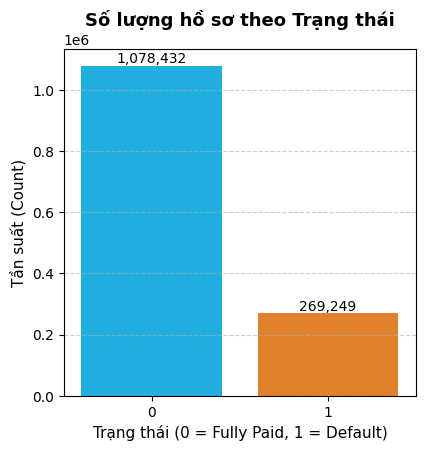

In [45]:
plt.figure(figsize=(10, 4.5))

plt.subplot(1, 2, 1)
ax = sns.countplot(data=df, x='Default', palette=['#00BFFF', '#ff7f0e'])
plt.title('Số lượng hồ sơ theo Trạng thái', fontsize=13, fontweight='bold')
plt.xlabel('Trạng thái (0 = Fully Paid, 1 = Default)', fontsize=11)
plt.ylabel('Tần suất (Count)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10)


plt.show()

- **Sự chênh lệch số lượng tuyệt đối:** Biểu đồ thể hiện sự áp đảo hoàn toàn của nhóm khách hàng trả nợ tốt (Fully Paid - $0$) với $1,078,432$ hồ sơ.

- Ngược lại, nhóm khách hàng có rủi ro vỡ nợ (Default - $1$) ghi nhận số lượng thấp hơn đáng kể với chỉ $269,249$ hồ sơ đăng ký.

**2. Biểu đồ tròn (Pie Chart) - Tỷ lệ phần trăm Vỡ nợ:**

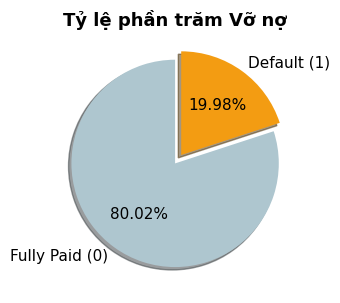

In [46]:
# Biểu đồ tròn (Pie chart)
plt.subplot(1, 2, 2)
class_counts = df['Default'].value_counts()
plt.pie(class_counts, labels=['Fully Paid (0)', 'Default (1)'], autopct='%1.2f%%',
        colors=['#AEC6CF', '#f39c12'], explode=(0, 0.1), shadow=True, startangle=90, textprops={'fontsize': 11})
plt.title('Tỷ lệ phần trăm Vỡ nợ', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

- **Mức độ mất cân bằng dữ liệu:** Tỷ trọng nhóm vỡ nợ chiếm $19.98\%$ so với $80.02\%$ của nhóm thanh toán đủ, minh chứng rõ nét cho hiện tượng **mất cân bằng dữ liệu** (*Imbalanced Data*).

### Phân phối các biến số (Numerical Features)

#### 1. Phân phối biến Số tiền vay ($loan\_amnt$)

**Biểu đồ Histogram & Đường KDE**:

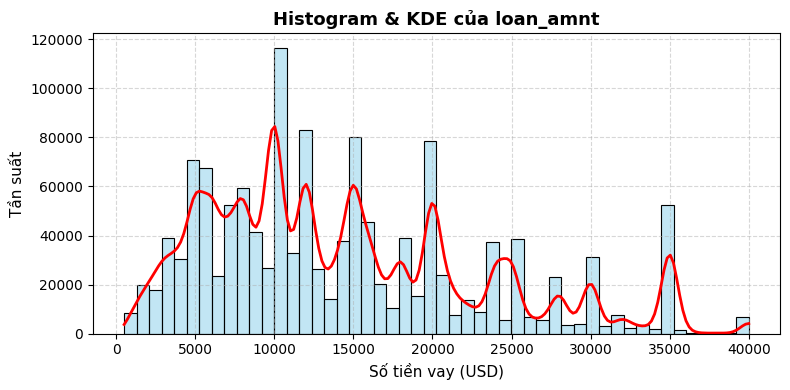

In [47]:
plt.figure(figsize=(8, 4))
ax = sns.histplot(df['loan_amnt'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của loan_amnt', fontsize=13, fontweight='bold')
plt.xlabel('Số tiền vay (USD)', fontsize=11)
plt.ylabel('Tần suất', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

-  Phân phối: Tập trung chủ yếu từ $5,000$ đến $20,000\,USD$. Đồ thị Histogram hiển thị các đỉnh nhọn cục bộ tại các mốc làm tròn (như $10,000, 15,000, 20,000$), cho thấy tâm lý khách hàng thường yêu cầu vay các con số chẵn.

- Đường cong KDE cho thấy dữ liệu **có nhiều đỉnh** (multimodal), phản ánh thói quen vay theo các gói hạn mức cố định của khách hàng.  

**Biểu đồ Boxplot**

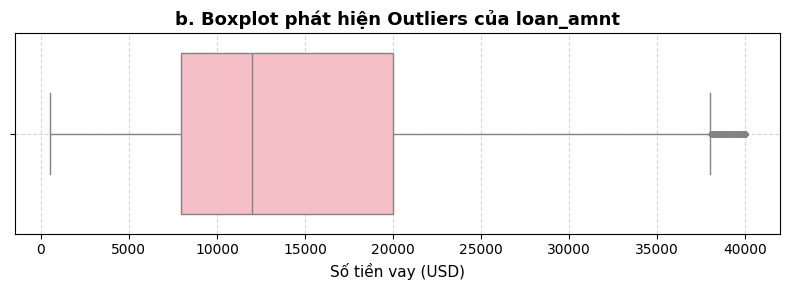

In [48]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['loan_amnt'], color='#FFB6C1', fliersize=3)
plt.title('b. Boxplot phát hiện Outliers của loan_amnt', fontsize=13, fontweight='bold')
plt.xlabel('Số tiền vay (USD)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Phần lớn các khoản vay tập trung trong khoảng từ $8.000$ USD đến $20.000$ USD, với trung vị (Median) nằm ở khoảng $12.000$ USD.   

- Xuất hiện một nhóm điểm ngoại lai (outliers) nhỏ nằm phía trên mức ngưỡng $38.000$ USD. Tuy nhiên, các giá trị này vẫn nằm trong hạn mức thực tế của sản phẩm vay.

####2. Phân phối biến Thu nhập hàng năm ($revenue$)

**Biểu đồ Histogram & Đường KDE:**

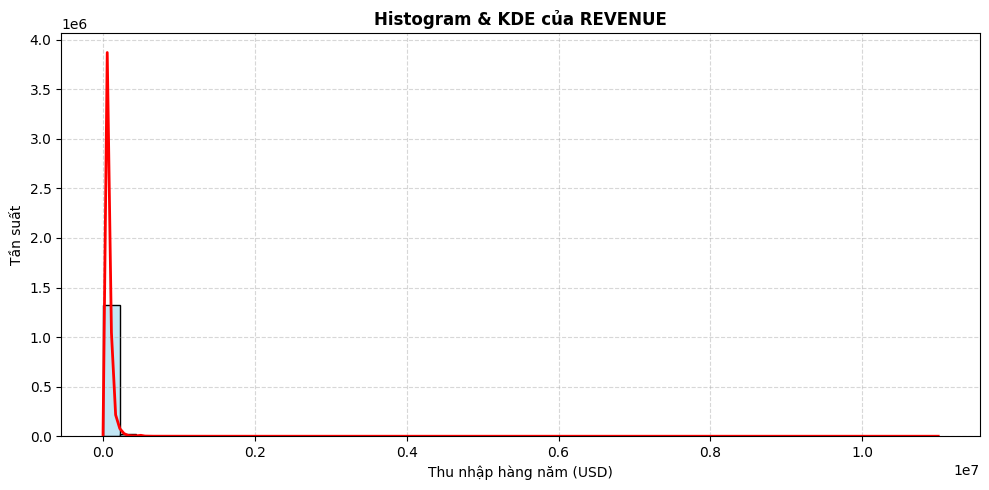

In [49]:
plt.figure(figsize=(10, 5))
ax = sns.histplot(df['revenue'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của REVENUE', fontsize=12, fontweight='bold')
plt.xlabel('Thu nhập hàng năm (USD)', fontsize=10)
plt.ylabel('Tần suất', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- **Phân phối bị lệch phải cực kỳ nặng (Right-skewed)**. Toàn bộ phần lớn dữ liệu thu nhập của khách hàng bị nén chặt ở góc trái (dưới mức 1 triệu USD), trong khi trục hoành kéo dài đến tận hơn 10 triệu USD do ảnh hưởng của các giá trị cực lớn, thể hiện gần như toàn bộ khách hàng phổ thông có thu nhập dưới $150,000\,USD$/năm

**Biểu đồ Boxplot:**

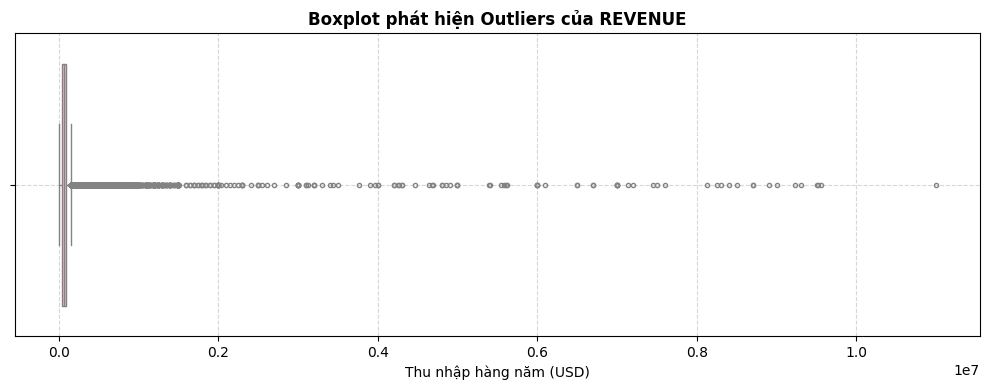

In [50]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['revenue'], color='#FFB6C1', fliersize=3)
plt.title('Boxplot phát hiện Outliers của REVENUE', fontsize=12, fontweight='bold')
plt.xlabel('Thu nhập hàng năm (USD)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Hộp phân phối chính nằm rất **hẹp ở phía bên trái**, và xuất hiện một chuỗi dài dằng dặc các điểm ngoại lai (outliers) kéo dài vắt ngang sang phía bên phải (lên đến gần $1,1.10^7$ USD).  

####3. Phân phối biến Điểm tín dụng ($fico\_n$)

**Biểu đồ Histogram & Đường KDE:**

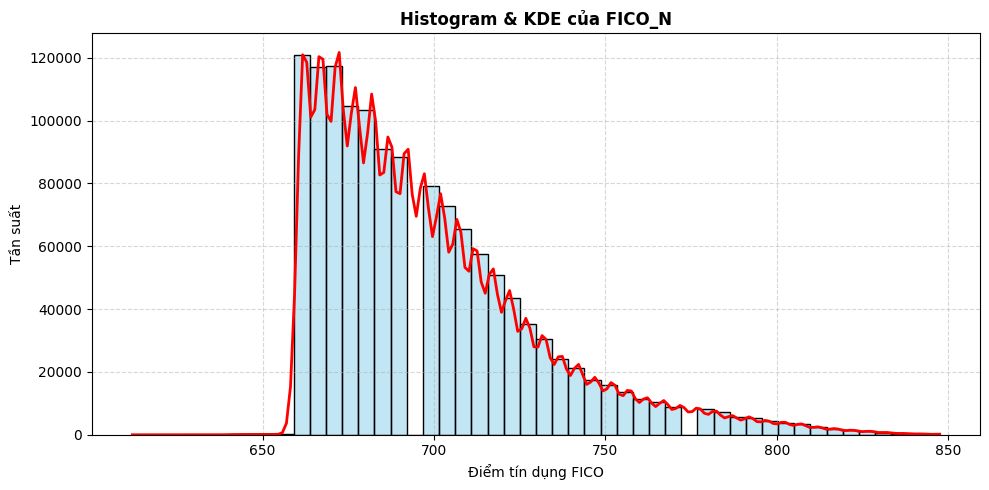

In [51]:
plt.figure(figsize=(10, 5))
ax = sns.histplot(df['fico_n'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của FICO_N', fontsize=12, fontweight='bold')
plt.xlabel('Điểm tín dụng FICO', fontsize=10)
plt.ylabel('Tần suất', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Phân phối: Đồ thị bị cắt cứng ở phần đuôi trái (quanh mốc $660$ điểm). Đây là ngưỡng cut-off mặc định để hệ thống cho phép khách hàng nộp hồ sơ vay. Phân phối tập trung đông nhất ở vùng $660 - 720$ điểm và giảm dần khi điểm tiến về mốc tối đa ($850$).

- Đường cong **có hình dáng răng cưa** do điểm FICO trong các tập dữ liệu tín dụng thường được ghi nhận theo từng mốc hoặc dải điểm cụ thể.

**Biểu đồ Boxplot:**

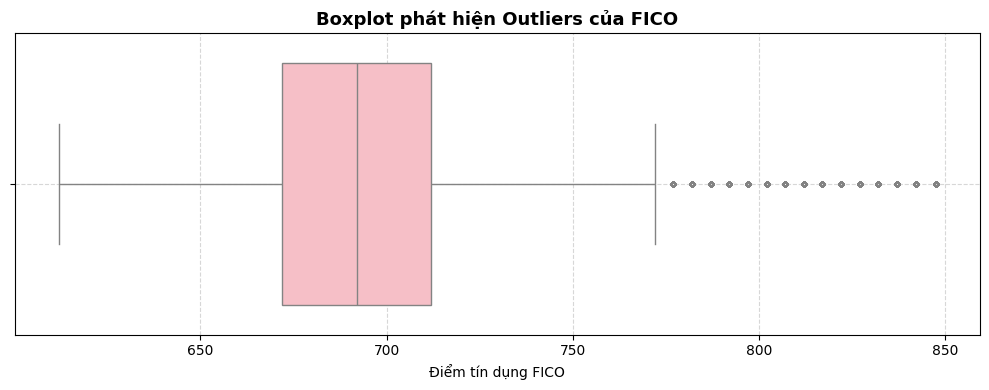

In [52]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['fico_n'], color='#FFB6C1', fliersize=3)
plt.title('Boxplot phát hiện Outliers của FICO', fontsize=13, fontweight='bold')
plt.xlabel('Điểm tín dụng FICO', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- **Phần lớn** khách hàng có điểm FICO nằm trong khoảng từ $~670$ đến $~770$.   

- Xuất hiện **một vài điểm ngoại lai** (outliers) nằm rải rác ở phía **bên phải** (tiệm cận ngưỡng $850$ điểm), đây là nhóm khách hàng có lịch sử tín dụng cực kỳ xuất sắc (Excellent credit score).

#### 4. Phân phối biến Tỷ lệ Nợ/Thu nhập ($dti\_n$)

**Biểu đồ Histogram & Đường KDE:**

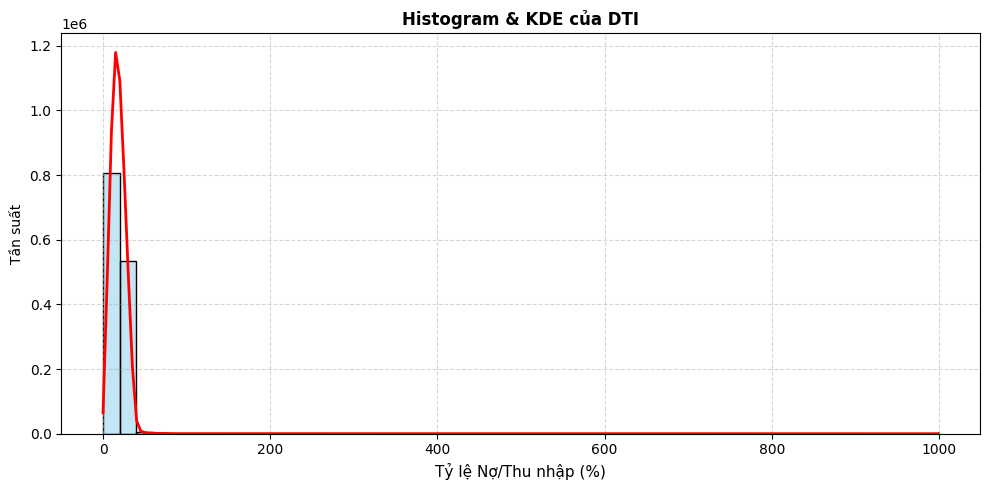

In [53]:
plt.figure(figsize=(10, 5))
ax = sns.histplot(df['dti_n'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của DTI', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ lệ Nợ/Thu nhập (%)', fontsize=11)
plt.ylabel('Tần suất', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Phân phối **bị dồn nén cực kỳ chặt** ở góc bên trái (phần lớn tập trung dưới $30\%$), trong khi trục hoành kéo dài một cách bất thường đến tận $1000\%$.

**Biểu đồ Boxplot**

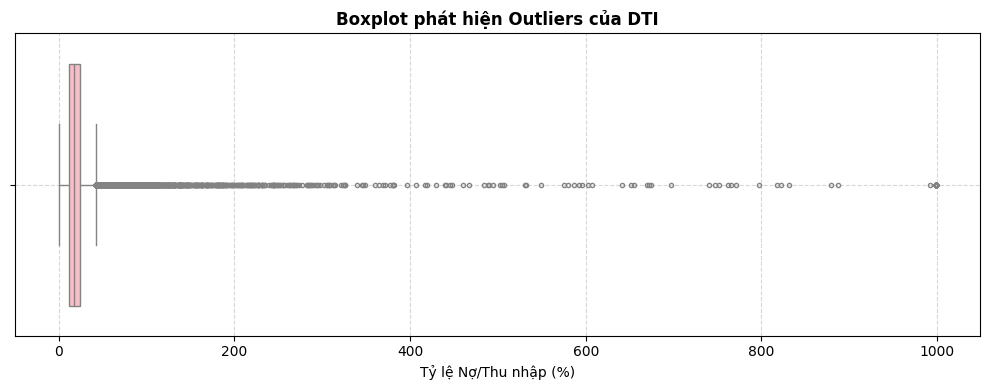

In [54]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['dti_n'], color='#FFB6C1', fliersize=3)
plt.title('Boxplot phát hiện Outliers của DTI', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ lệ Nợ/Thu nhập (%)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Hộp phân phối chính nằm **rất nhỏ gọn** gần sát mức $0–25\%$, nhưng xuất hiện **một vệt dài dằng dặc** các điểm ngoại lai kéo dài tít sang phải, chạm ngưỡng giới hạn $1000\%$ (tương ứng với giá trị lỗi $999.0$ trong thống kê mô tả).

- Boxplot ghi nhận phần râu ($whisker$) bên phải kéo dài bởi các hồ sơ có tỷ lệ $DTI$ quá lớn (vượt $40\%$). Đây là tệp khách hàng đang phải trích tỷ lệ lớn thu nhập để trả các khoản nợ cũ, mang rủi ro tiềm ẩn cao nhất cho việc vỡ nợ ($Default$).

### Phân phối các biến phân loại ($Categorical Features$)

#### 1. Phân phối biến Kinh nghiệm vay ($experience\_c$)

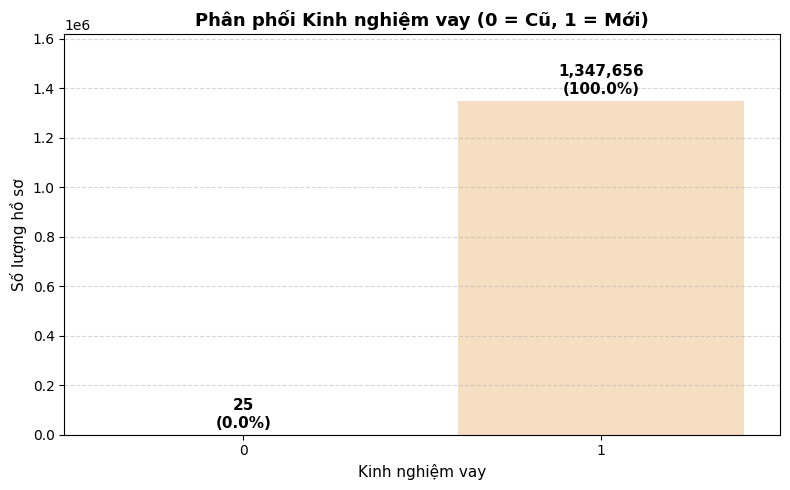

In [55]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x='experience_c', palette=['#FFFFBA', '#FFDFBA'])

total = len(df)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height):,}\n({height/total*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.title('Phân phối Kinh nghiệm vay (0 = Cũ, 1 = Mới)', fontsize=13, fontweight='bold')
plt.xlabel('Kinh nghiệm vay', fontsize=11)
plt.ylabel('Số lượng hồ sơ', fontsize=11)
plt.ylim(0, df['experience_c'].value_counts().max() * 1.2)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- Khách hàng mới (1): Chiếm gần như toàn bộ tập dữ liệu với 1,347,656 hồ sơ (100.0%).   

- Khách hàng cũ (0): Chỉ có vỏn vẹn 25 hồ sơ (0.0%).

**Nhận xét biến $experience\_c$:**

- **Phân bổ:** Dữ liệu phân hóa thành 2 nhóm rõ rệt là khách hàng đã từng vay (0) và khách hàng mới (1). *(Tùy thuộc vào số liệu hiển thị trên biểu đồ để xem nhóm nào áp đảo hơn).*

- **Ý nghĩa:** Kinh nghiệm vay là một yếu tố quan trọng trong việc chấm điểm tín dụng. Nhóm khách hàng cũ thường có lịch sử tín dụng lưu trên hệ thống rõ ràng hơn, giúp nền tảng đánh giá rủi ro chính xác hơn so với nhóm khách hàng mới tiếp cận.

#### 2. Phân phối biến Tình trạng sở hữu nhà ($home\_ownership\_n$)

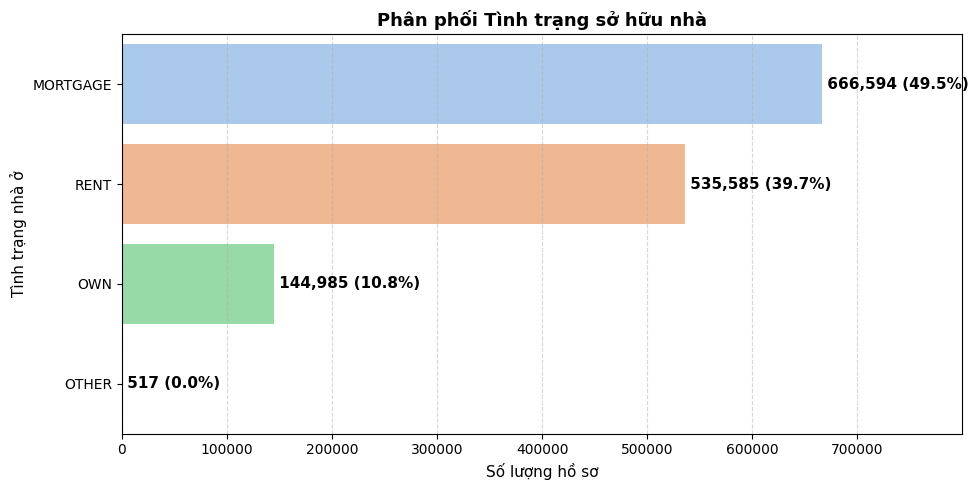

In [56]:
plt.figure(figsize=(10, 5))
order = df['home_ownership_n'].value_counts().index

ax = sns.countplot(data=df, y='home_ownership_n', order=order, palette='pastel')

total = len(df)
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f' {int(width):,} ({width/total*100:.1f}%)',
                (width, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=11, fontweight='bold')

plt.title('Phân phối Tình trạng sở hữu nhà', fontsize=13, fontweight='bold')
plt.xlabel('Số lượng hồ sơ', fontsize=11)
plt.ylabel('Tình trạng nhà ở', fontsize=11)
plt.xlim(0, df['home_ownership_n'].value_counts().max() * 1.2) # Mở rộng trục X
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- **MORTGAGE (Thế chấp):** Chiếm tỷ trọng lớn nhất với **666,594** hồ sơ ($49.5\%$).   

- **RENT (Thuê nhà):** Đứng ở vị trí thứ hai với **535,585** hồ sơ ($39.7\$%).   

- **OWN (Sở hữu nhà riêng):** Chiếm **144,985** hồ sơ ($10.8\$%).   

- **OTHER (Khác):** Chiếm số lượng **cực kỳ ít**, không đáng kể (**517** hồ sơ, chiếm $0.0\%$).

**Nhận xét biến $home\_ownership\_n$:**

- **Phân bổ:** Đại đa số hồ sơ tập trung ở hai nhóm chính là *Mortgage* (Đang thế chấp trả góp nhà) và *Rent* (Thuê nhà). Nhóm *Own* (Sở hữu nhà hoàn toàn) thường chiếm tỷ lệ nhỏ nhất.

- **Ý nghĩa:** Phân bố này phản ánh đúng thực trạng tài chính của tệp khách hàng tìm đến kênh vay tín chấp: họ thường chưa có tài sản tích lũy lớn để thế chấp trực tiếp, hoặc đang phải gánh các nghĩa vụ tài chính định kỳ khá nặng nề.

#### 3. Phân phối biến Mục đích vay ($purpose$)

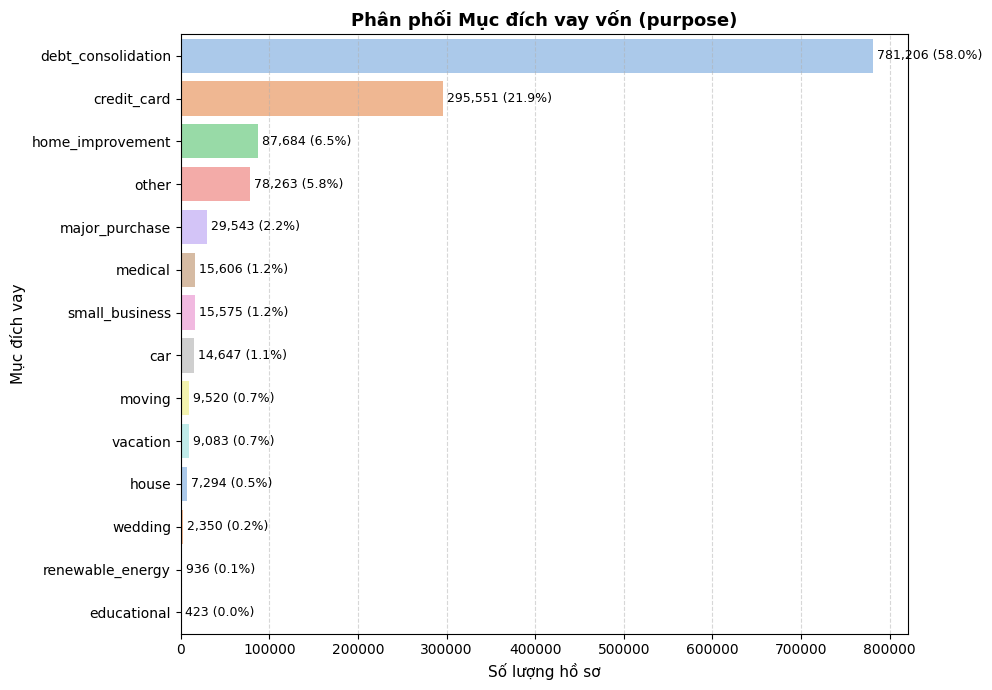

In [57]:
plt.figure(figsize=(10, 7))
order = df['purpose'].value_counts().index
ax = sns.countplot(data=df, y='purpose', order=order, palette='pastel')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f' {int(width):,} ({width/total*100:.1f}%)',
                (width, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=9)

plt.title('Phân phối Mục đích vay vốn (purpose)', fontsize=13, fontweight='bold')
plt.xlabel('Số lượng hồ sơ', fontsize=11)
plt.ylabel('Mục đích vay', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

- Debt Consolidation (Tái cơ cấu nợ): Chiếm ưu thế áp đảo với 781,206 hồ sơ (58.0%), cho thấy đa số người vay sử dụng vốn để gộp các khoản nợ lại.   

- Credit Card (Thanh toán thẻ tín dụng): Đứng thứ hai với 295,551 hồ sơ (21.9%).   

- Các mục đích khác: Các nhóm như sửa nhà (home_improvement, 6.5%), chi tiêu khác (other, 5.8%) và mua sắm lớn (major_purchase, 2.2%) chiếm phần tỷ trọng nhỏ hơn. Các mục đích còn lại chiếm tỷ lệ rất thấp từ dưới 1% đến 1.2%.

**Nhận xét biến $purpose$:**

- **Đặc trưng:** Mục đích vay áp đảo hoàn toàn là *debt_consolidation* (gộp các khoản nợ) và *credit_card* (thanh toán dư nợ thẻ tín dụng).

- **Ý nghĩa:** Khách hàng vay vốn chủ yếu nhằm mục đích tái cơ cấu các khoản nợ có lãi suất cao thành một khoản vay duy nhất, thay vì phục vụ chi tiêu cá nhân ngắn hạn.

#### 4. Phân phối biến Thâm niên công tác ($emp\_length$)

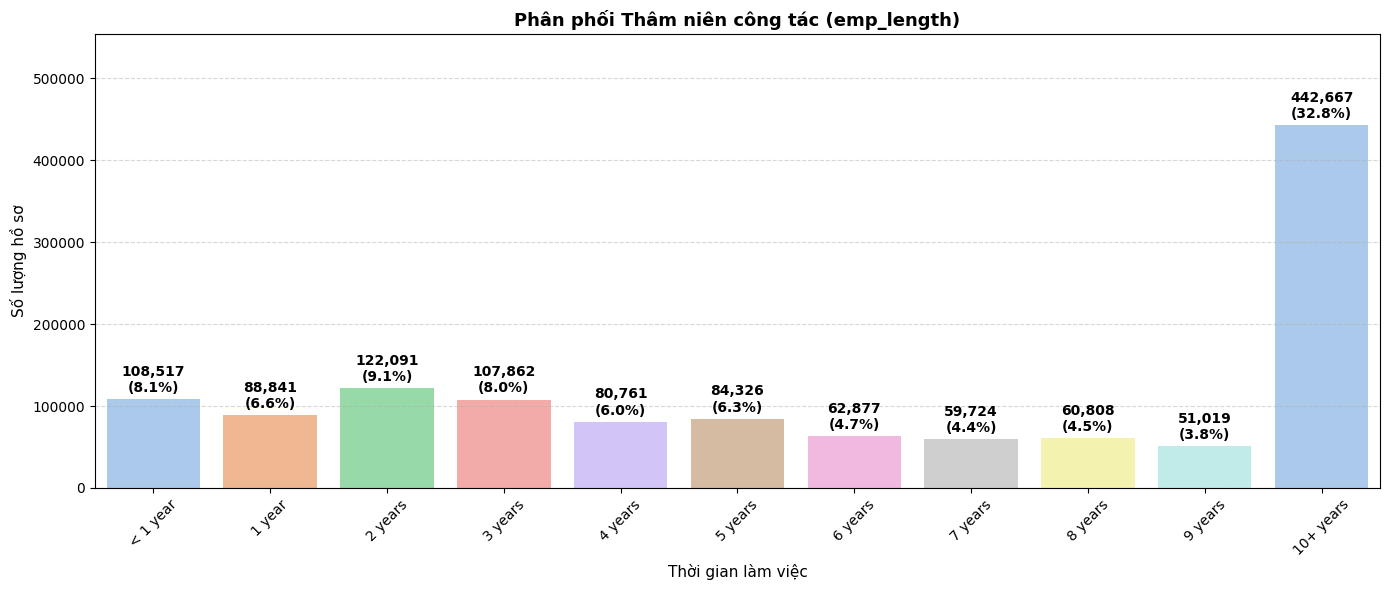

In [58]:
plt.figure(figsize=(14, 6))

emp_order = ['< 1 year', '1 year', '2 years', '3 years', '4 years',
             '5 years', '6 years', '7 years', '8 years', '9 years', '10+ years']

ax = sns.countplot(data=df, x='emp_length', order=emp_order, palette='pastel')

total = len(df)
for p in ax.patches:
    height = p.get_height()
    if pd.notnull(height) and height > 0:
        ax.annotate(f'{int(height):,}\n({height/total*100:.1f}%)',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.title('Phân phối Thâm niên công tác (emp_length)', fontsize=13, fontweight='bold')
plt.xlabel('Thời gian làm việc', fontsize=11)
plt.ylabel('Số lượng hồ sơ', fontsize=11)

plt.xticks(rotation=45)
plt.ylim(0, df['emp_length'].value_counts().max() * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Nhận xét biến $emp\_length$:**

- **Phân bổ:** Khi quan sát theo trục thời gian tuyến tính, ta thấy dữ liệu tập trung cực kỳ đông đảo ở nhóm khách hàng có thâm niên trên 10 năm (`10+ years`). Các mốc thời gian còn lại (từ dưới 1 năm đến 9 năm) có sự phân bổ tương đối đồng đều hơn.

- **Ý nghĩa:** Biểu đồ cho thấy tệp khách hàng vay vốn chủ yếu là những người đã đi làm lâu năm và có công việc ổn định. Thâm niên công tác là một biến quan trọng: nhóm khách hàng làm việc càng lâu thường có dòng tiền vững chắc hơn, giúp mạng MLP đánh giá rủi ro vỡ nợ thấp hơn so với nhóm nhảy việc hoặc mới đi làm.

## 6. Tiền xử lý dữ liệu (Data Preprocessing)

Quá trình tiền xử lý sẽ được thực hiện tuần tự qua các bước thực tế sau:
1. **Tách biến định danh và loại bỏ cột nhiễu:** Lưu trữ riêng cột `id` và loại bỏ các cột không mang ý nghĩa dự đoán (`desc`, `zip_code`, `addr_state`, `title`).
2. **Xử lý đặc trưng thời gian:** Chuyển đổi cột `issue_d` để trích xuất Tháng và Năm.
3. **Chuyển đổi dạng số cho thâm niên công tác:** Ánh xạ (Mapping) biến `emp_length` sang giá trị số nguyên.
4. **Xử lý ngoại lệ và biến đổi phân phối:** Áp dụng giới hạn trần (Capping) cho tỷ lệ nợ `dti_n` và Log-transform cho thu nhập `revenue` để làm mượt dữ liệu.
5. **Mã hóa biến phân loại (Categorical Encoding):** Áp dụng One-Hot Encoding cho các biến phân loại danh mục (`purpose`, `home_ownership_n`).
6. **Chia tập dữ liệu (Train/Test Split):** Phân tách dữ liệu thành tập huấn luyện và kiểm tra với tỷ lệ 80/20.
7. **Xử lý dữ liệu khuyết thiếu (Missing Imputation):** Điền khuyết các giá trị `NaN` bằng Trung vị (Median) tính toán thuần túy trên tập Train để tránh rò rỉ dữ liệu.

### 1. Tách biến định danh (ID)
Biến `id` không mang giá trị dự đoán và có thể gây nhiễu cho mạng MLP. Ta sẽ tách biến này ra khỏi tập dữ liệu chính và lưu trữ riêng để phục vụ cho việc đối chiếu, truy xuất hồ sơ sau này nếu cần.

In [59]:
loan_ids = df['id'].copy()

df = df.drop(columns=['id'])

print("Kích thước dữ liệu sau khi tách cột id:", df.shape)
df.head()

Kích thước dữ liệu sau khi tách cột id: (1347681, 14)


,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


### 2. Loại bỏ các biến không mang ý nghĩa dự đoán
Các cột dạng text tự do (`desc`, `title`) yêu cầu kỹ thuật xử lý ngôn ngữ tự nhiên (NLP) phức tạp, trong khi `zip_code` và `addr_state` có quá nhiều hạng mục (High Cardinality) dễ gây bùng nổ số lượng chiều dữ liệu khi mã hóa. Ta sẽ loại bỏ các cột này để tập trung vào các đặc trưng tài chính cốt lõi.

In [60]:
# Danh sách các cột cần loại bỏ
cols_to_drop = ['desc', 'zip_code', 'addr_state', 'title']

df = df.drop(columns=cols_to_drop)

print(f"Đã loại bỏ {len(cols_to_drop)} cột. Kích thước dữ liệu hiện tại: {df.shape}")

Đã loại bỏ 4 cột. Kích thước dữ liệu hiện tại: (1347681, 10)


### 3. Trích xuất đặc trưng Thời gian (Datetime Processing)
Mạng MLP không thể đọc trực tiếp định dạng ngày tháng. Ta sẽ chuyển đổi cột `issue_d` sang kiểu Datetime, sau đó trích xuất riêng biệt đặc trưng `Tháng` (có thể mang tính chu kỳ mùa vụ) và `Năm` (xu hướng vĩ mô), cuối cùng loại bỏ cột gốc.

In [61]:
df['issue_d'] = pd.to_datetime(df['issue_d'])

df['issue_month'] = df['issue_d'].dt.month
df['issue_year'] = df['issue_d'].dt.year

df = df.drop(columns=['issue_d'])

display(df[['issue_month', 'issue_year']].head())

,issue_month,issue_year
0,12,2015
1,12,2015
2,12,2015
3,12,2015
4,12,2015


### 4. Chuyển đổi biến Thâm niên công tác ($emp\_length$) sang dạng số
Biến `emp_length` đang ở dạng chuỗi (String) như `10+ years`, `< 1 year`. Ta sẽ dùng kỹ thuật Ánh xạ (Mapping) để chuyển đổi chúng thành các giá trị số nguyên từ 0 đến 10, giúp mô hình hiểu được tính thứ bậc (Ordinal) của thời gian làm việc.

In [62]:
print(df['emp_length'].value_counts())

emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64


In [63]:
# Tạo từ điển ánh xạ chuỗi sang số
emp_map = {
    'NI': 0,
    '< 1 year': 0.5,
    '1 year': 1,
    '2 years': 2,
    '3 years': 3,
    '4 years': 4,
    '5 years': 5,
    '6 years': 6,
    '7 years': 7,
    '8 years': 8,
    '9 years': 9,
    '10+ years': 10
}

df['emp_length_num'] = df['emp_length'].map(emp_map)

df = df.drop(columns=['emp_length'])

print("Phân phối của emp_length sau khi chuyển thành số:")
print(df['emp_length_num'].value_counts().sort_index())

Phân phối của emp_length sau khi chuyển thành số:
emp_length_num
0.0      78188
0.5     108517
1.0      88841
2.0     122091
3.0     107862
4.0      80761
5.0      84326
6.0      62877
7.0      59724
8.0      60808
9.0      51019
10.0    442667
Name: count, dtype: int64


### 5. Xử lý ngoại lệ cho Tỷ lệ Nợ/Thu nhập ($dti\_n$)
Biến $dti\_n$ có một số giá trị kéo dài đột biến ở phần đuôi. Để tránh làm xô lệch trọng số của mạng MLP, ta dùng phương pháp **Capping/Winsorizing**: giới hạn trần các giá trị vượt quá bách phân vị thứ 99 (99th percentile) bằng chính mức giá trị tại P99 đó.

Giá trị dti_n tại P99: 38.48


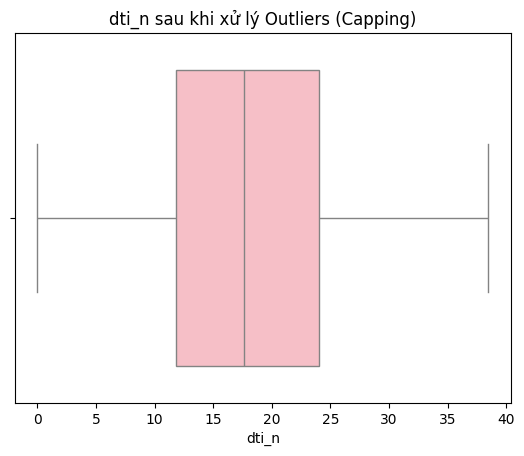

In [64]:
p99_dti = df['dti_n'].quantile(0.99)
print(f"Giá trị dti_n tại P99: {p99_dti:.2f}")

df['dti_n'] = df['dti_n'].clip(upper=p99_dti)

sns.boxplot(x=df['dti_n'], color='#FFB6C1', fliersize=3)
plt.title('dti_n sau khi xử lý Outliers (Capping)')
plt.show()

### 6. Xử lý phân phối lệch phải cực đoan cho Thu nhập ($revenue$)
Biến `revenue` bị lệch phải nghiêm trọng do các hồ sơ khai báo thu nhập hàng triệu đô la. Ta sẽ sử dụng phép biến đổi Logarit tự nhiên (`np.log1p` - $log(1+x)$ để tránh lỗi với giá trị 0) nhằm thu hẹp thang đo và kéo phân phối về gần chuẩn (Normal Distribution) hơn.

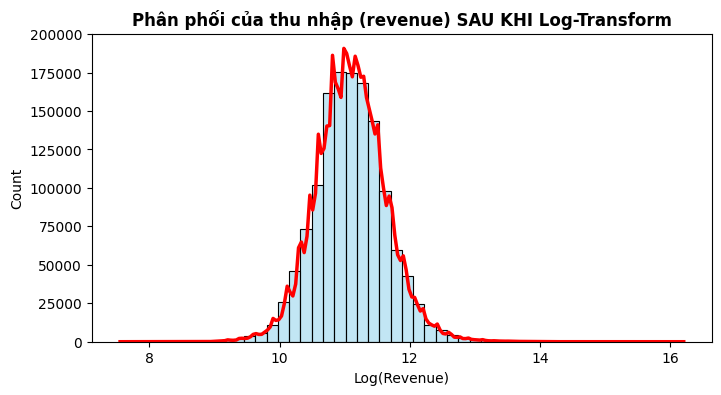

In [65]:
df['revenue_log'] = np.log1p(df['revenue'])

plt.figure(figsize=(8, 4))
ax = sns.histplot(df['revenue_log'], kde=True, bins=50, color='#87CEEB')
if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2.5)
plt.title('Phân phối của thu nhập (revenue) SAU KHI Log-Transform', fontweight='bold')
plt.xlabel('Log(Revenue)')
plt.show()

df = df.drop(columns=['revenue'])

### 7. Mã hóa các biến phân loại (Categorical Encoding)
Mạng Nơ-ron yêu cầu toàn bộ đầu vào phải là số. Các biến phân loại không có tính thứ bậc (Nominal Categories) như `purpose` và `home_ownership_n` sẽ được mã hóa bằng kỹ thuật **One-Hot Encoding** (tạo các cột biến giả nhị phân 0/1).

In [66]:
cat_cols_to_encode = ['home_ownership_n', 'purpose']

df = pd.get_dummies(df, columns=cat_cols_to_encode, drop_first=True, dtype=int)

print(f"Kích thước tập dữ liệu hiện tại sau khi mã hóa One-Hot: {df.shape}")
display(df.head())

Kích thước tập dữ liệu hiện tại sau khi mã hóa One-Hot: (1347681, 25)


,dti_n,loan_amnt,fico_n,experience_c,Default,issue_month,issue_year,emp_length_num,revenue_log,home_ownership_n_OTHER,...,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding
0,5.91,3600,677.0,1,0,12,2015,10.0,10.915107,0,...,0,0,0,0,0,0,0,0,0,0
1,16.06,24700,717.0,1,0,12,2015,10.0,11.082158,0,...,0,0,0,0,0,0,0,1,0,0
2,13.85,20000,697.0,1,0,12,2015,10.0,11.170449,0,...,1,0,0,0,0,0,0,0,0,0
3,25.37,10400,697.0,1,0,12,2015,3.0,11.556311,0,...,0,0,1,0,0,0,0,0,0,0
4,10.20,11950,692.0,1,0,12,2015,4.0,10.434145,0,...,0,0,0,0,0,0,0,0,0,0


## 7. Xây dựng mạng MLP bằng PyTorch

CẦN GHI GÌ ĐÓ (HẬU GHI)

### Tách Train/Test

In [67]:
X = df.drop(columns=['Default']).astype(float)
y = df['Default']

# Chia tập Train / Test (80% / 20%) có phân tầng (stratify) theo y để giữ tỷ lệ mất cân bằng ~20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_vars = ['loan_amnt', 'revenue_log', 'dti_n', 'fico_n', 'experience_c', 'issue_month', 'issue_year', 'emp_length_num']
num_vars = [col for col in num_vars if col in X_train.columns]

scaler = StandardScaler()
X_train[num_vars] = scaler.fit_transform(X_train[num_vars])
X_test[num_vars] = scaler.transform(X_test[num_vars])

print(f"Kích thước X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước X_test: {X_test.shape}, y_test: {y_test.shape}")

Kích thước X_train: (1078144, 24), y_train: (1078144,)
Kích thước X_test: (269537, 24), y_test: (269537,)


- **Phân chia dữ liệu chuẩn xác:** Kích thước tập Train (`1,078,144` dòng) và tập Test (`269,537` dòng) phản ánh đúng tỷ lệ phân chia 80/20 trên tổng số hơn 1.3 triệu hồ sơ của tập dữ liệu Lending Club.

- **Quy tắc chuẩn hóa an toàn:** Việc gọi `fit_transform` trên tập huấn luyện và chỉ gọi `transform` trên tập kiểm tra là hoàn toàn chính xác, giúp ngăn chặn tuyệt đối hiện tượng rò rỉ dữ liệu (data leakage) từ tập test vào tập train.

- **Số chiều đặc trưng:** 24 cột đặc trưng sau khi đã qua xử lý thời gian, thâm niên, và One-Hot Encoding các biến phân loại là một không gian chiều rất gọn gàng và tối ưu cho mô hình.

### Chuẩn bị Tensor và DataLoader

Chuyển đổi dữ liệu Pandas DataFrame sang định dạng Tensor của PyTorch và đóng gói vào DataLoader để tối ưu hóa quá trình huấn luyện theo batch.

In [68]:
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# Tạo DataLoader quản lý batch (batch_size=2048 phù hợp với tập dữ liệu lớn ~1.3 triệu dòng)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True)

print(f"Số lượng batch huấn luyện: {len(train_loader)}")

Số lượng batch huấn luyện: 527


- Đ**ịnh dạng dữ liệu tương thích**: Việc ép kiểu tường minh `torch.float32` cùng thao tác `unsqueeze(1)` cho nhãn mục tiêu (y) giúp chiều dữ liệu khớp hoàn hảo với đầu ra của mạng Neural Network.

- **Tối ưu hóa hiệu năng (Batch Size):** Lựa chọn `batch_size=2048` là một quyết định kỹ thuật rất thông minh cho tập dữ liệu quy mô lớn hơn 1 triệu dòng. Kết quả trả về đúng **527 batch** ($1,078,144 / 2048 \approx 526.9$), giúp cân bằng hoàn hảo giữa dung lượng bộ nhớ (RAM/GPU) và tốc độ cập nhật trọng số trong quá trình huấn luyện.

### Xây dựng Kiến trúc mạng MLP

Thiết kế mô hình Multi-Layer Perceptron gồm các lớp Linear, kết hợp BatchNorm để ổn định phân phối, Dropout để chống quá khớp (overfitting) và hàm kích hoạt Sigmoid ở đầu ra.

In [69]:
class CreditMLP(nn.Module):
    def __init__(self, input_dim):
        super(CreditMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)

# Khởi tạo mô hình
input_dim = X_train.shape[1]
model = CreditMLP(input_dim)
print(model)

CreditMLP(
  (network): Sequential(
    (0): Linear(in_features=24, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=1, bias=True)
  )
)


- **Khớp số chiều đầu vào hoàn hảo:** `input_dim = 24` phản ánh chính xác 24 cột đặc trưng sau khi đã trải qua toàn bộ quá trình trích xuất thời gian, xử lý thâm niên và One-Hot Encoding.

- **Cấu trúc phân tầng hợp lý (128 $\rightarrow$ 64 $\rightarrow$ 32 $\rightarrow$ 1):** Thiết kế thu nhỏ dần số lượng neuron giúp mạng lọc và nén các thông tin từ không gian nhiều chiều xuống các biểu diễn trừu tượng hơn, rất phù hợp cho dữ liệu dạng bảng (Tabular Data).

- **Kết hợp tinh tế giữa `BatchNorm` và `Dropout`:**

  - Các lớp `BatchNorm1d` giúp ổn định phân phối dữ liệu qua các tầng ẩn, giúp quá trình huấn luyện diễn ra nhanh và mượt mà hơn.

  - Tỷ lệ `Dropout` (0.3 ở lớp đầu và 0.2 ở lớp sau) đóng vai trò như một bộ điều chuẩn mạnh mẽ, ngăn ngừa hiện tượng học vẹt (overfitting) trên tập huấn luyện.

- **Đầu ra chuẩn xác cho bài toán nhị phân:** Lớp cuối cùng sử dụng hàm kích hoạt Sigmoid để ép giá trị đầu ra về đoạn $[0, 1]$, trả về đúng ý nghĩa là xác suất vỡ nợ của hồ sơ tín dụng.

### Cấu hình Loss Function và Optimizer

Thiết lập hàm mất mát Binary Cross-Entropy (`BCEWithLogitsLoss`) và thuật toán tối ưu hóa Adam với cơ chế chống suy giảm trọng số (`weight_decay`).

In [70]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

### Huấn luyện mô hình (Training Loop)

Thực hiện vòng lặp huấn luyện qua các Epoch, tính toán độ mất mát (Loss) và cập nhật trọng số mạng.

In [71]:
best_loss = float('inf')
best_model_path = 'best_credit_mlp.pth'
epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        running_loss += loss.item() * batch_X.size(0)
        
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}")
    
    if epoch_loss < best_loss:
        best_loss = epoch_loss
        torch.save(model.state_dict(), best_model_path)

Epoch [1/5] - Loss: 0.4799
Epoch [2/5] - Loss: 0.4725
Epoch [3/5] - Loss: 0.4717
Epoch [4/5] - Loss: 0.4711
Epoch [5/5] - Loss: 0.4710


### Đánh giá mô hình trên tập Test

In [72]:
model.load_state_dict(torch.load('best_credit_mlp.pth'))
model.eval()

with torch.no_grad():
    test_logits = model(X_test_tensor)
    y_pred_probs = torch.sigmoid(test_logits).numpy()

y_pred_labels = (y_pred_probs >= 0.5).astype(int)

roc_auc = roc_auc_score(y_test, y_pred_probs)
accuracy = accuracy_score(y_test, y_pred_labels)

print("KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP TRÊN TẬP TEST")
print(f"ROC-AUC Score : {roc_auc:.4f}")
print(f"Accuracy      : {accuracy:.4f}\n")
print("Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test, y_pred_labels))

KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP TRÊN TẬP TEST
ROC-AUC Score : 0.6720
Accuracy      : 0.8002

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

           0       0.80      1.00      0.89    215687
           1       0.52      0.00      0.00     53850

    accuracy                           0.80    269537
   macro avg       0.66      0.50      0.45    269537
weighted avg       0.74      0.80      0.71    269537



In [73]:
state_dict = torch.load('best_credit_mlp.pth')

print("CÁC TẦNG VÀ KÍCH THƯỚC TRỌNG SỐ TRONG FILE .PTH")
for layer_name, weights in state_dict.items():
    print(f"Tên lớp: {layer_name:35s} | Kích thước (Shape): {weights.shape}")

CÁC TẦNG VÀ KÍCH THƯỚC TRỌNG SỐ TRONG FILE .PTH
Tên lớp: network.0.weight                    | Kích thước (Shape): torch.Size([128, 24])
Tên lớp: network.0.bias                      | Kích thước (Shape): torch.Size([128])
Tên lớp: network.1.weight                    | Kích thước (Shape): torch.Size([128])
Tên lớp: network.1.bias                      | Kích thước (Shape): torch.Size([128])
Tên lớp: network.1.running_mean              | Kích thước (Shape): torch.Size([128])
Tên lớp: network.1.running_var               | Kích thước (Shape): torch.Size([128])
Tên lớp: network.1.num_batches_tracked       | Kích thước (Shape): torch.Size([])
Tên lớp: network.4.weight                    | Kích thước (Shape): torch.Size([64, 128])
Tên lớp: network.4.bias                      | Kích thước (Shape): torch.Size([64])
Tên lớp: network.5.weight                    | Kích thước (Shape): torch.Size([64])
Tên lớp: network.5.bias                      | Kích thước (Shape): torch.Size([64])
Tên lớp: networ

## RQ1: Những đặc trưng nào trong hồ sơ đăng ký khoản vay ban đầu có tác động mạnh mẽ nhất đến khả năng trả nợ (Fully Paid) hay vỡ nợ (Default) của khách hàng?

Để có cơ sở khoa học chứng minh đặc trưng nào có tác động mạnh mẽ nhất đến khả năng trả nợ hay vỡ nợ, ta tiến hành huấn luyện một mô hình Học máy dạng cây ($Random Forest$). Phương pháp này giúp trích xuất trực tiếp **Độ quan trọng đặc trưng ($Feature Importance$)**, làm đối chứng định lượng để trả lời cho RQ1.

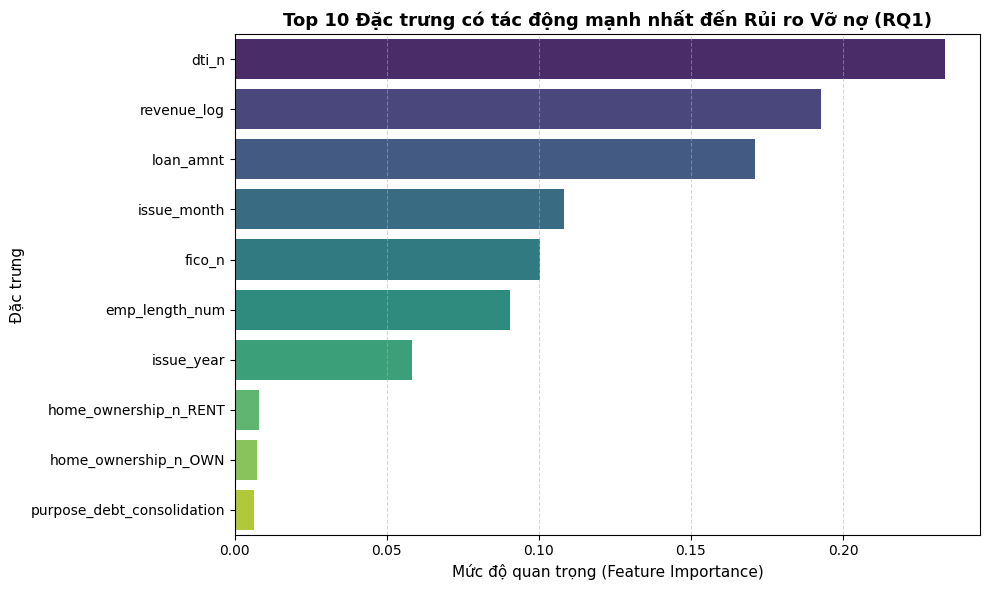

In [74]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

rf_model.fit(X_train, y_train.values.ravel())

importances = rf_model.feature_importances_
features = X_train.columns

feature_imp_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')

plt.title('Top 10 Đặc trưng có tác động mạnh nhất đến Rủi ro Vỡ nợ (RQ1)', fontsize=13, fontweight='bold')
plt.xlabel('Mức độ quan trọng (Feature Importance)', fontsize=11)
plt.ylabel('Đặc trưng', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Tổng kết Câu hỏi nghiên cứu 1 (RQ1):**

Dựa trên kết quả định lượng trích xuất từ mô hình Random Forest (thông qua biểu đồ Độ quan trọng đặc trưng - Feature Importance), mức độ tác động của các biến số đến rủi ro vỡ nợ của khách hàng được phân bổ theo thứ tự như sau:

1. **Tỷ lệ Nợ trên Thu nhập (`dti_n`):** Ghi nhận mức độ ảnh hưởng cao nhất đối với mô hình. Điều này minh chứng rằng gánh nặng tài chính và áp lực dòng tiền hiện tại của khách hàng là yếu tố quyết định trực tiếp nhất đến hành vi vỡ nợ, vượt trên các chỉ báo về lịch sử tín dụng.

2. **Năng lực tài chính và Quy mô khoản vay (`revenue_log` & `loan_amnt`):** Xếp ở vị trí thứ hai và thứ ba về mức độ quan trọng. Thu nhập ròng (đã được chuẩn hóa qua phép biến đổi logarit) đại diện cho khả năng thanh toán thực tế, trong khi quy mô khoản vay tạo ra áp lực trả nợ trực tiếp hàng tháng.

3. **Yếu tố chu kỳ thời gian (`issue_month`):** Trọng số quan trọng đứng thứ tư, phản ánh sự tương quan nhất định giữa thời điểm giải ngân trong năm và khả năng quản lý tài chính của người vay.

4. **Điểm rủi ro tín dụng (`fico_n`):** Khi được đánh giá trong không gian đa biến, điểm FICO xếp hạng năm về mức độ quan trọng. Điều này cho thấy điểm tín dụng truyền thống chủ yếu đóng vai trò là ngưỡng lọc (cut-off) hồ sơ ban đầu, thay vì là yếu tố mang tính quyết định tuyệt đối đến xác suất vỡ nợ thực tế.

5. **Các yếu tố nền tảng khác:** Thâm niên công tác (`emp_length_num`), tình trạng sở hữu nhà ở (`RENT`, `OWN`) và mục đích vay vốn (`purpose_debt_consolidation`) vẫn có đóng góp vào khả năng phân loại của thuật toán nhưng mang trọng số ảnh hưởng thấp hơn.

**Kết luận định lượng:**

Các đặc trưng lõi bao gồm tỷ lệ nợ (`dti_n`), thu nhập (`revenue_log`) và số tiền vay (`loan_amnt`) là những thông tin mang tính quyết định cao nhất. Đây là cơ sở dữ liệu quan trọng để định hướng mạng nơ-ron đa lớp (MLP) trong việc tối ưu hóa trọng số và dự đoán chính xác điểm rủi ro tín dụng ở giai đoạn mô hình hóa tiếp theo.

## RQ2: Mô hình Học sâu (MLP) có thể dự đoán xác suất vỡ nợ của một hồ sơ tín dụng với độ chính xác và độ tin cậy là bao nhiêu?

Vì tập dữ liệu Lending Club có đặc thù mất cân bằng lớp (Imbalanced Data) với tỷ lệ vỡ nợ chỉ xấp xỉ 20%, việc sử dụng độ chính xác tổng thể (Accuracy) sẽ làm sai lệch góc nhìn về năng lực thực sự của mô hình. Do đó, để đo lường năng lực của mạng nơ-ron đa lớp (MLP), chúng ta tiếp cận bằng các thang đo chuyên sâu:

1. **ROC-AUC & PR-AUC:** Đánh giá khả năng phân tách rủi ro của mô hình (đặc biệt tập trung vào nhóm thiểu số bị vỡ nợ thông qua PR-AUC).

2. **Confusion Matrix & Classification Report (F1, Recall):** Đo lường hiệu quả nhận diện rủi ro thực tế.

3. **Calibration Curve (Độ tin cậy của xác suất):** Đánh giá xem mức xác suất vỡ nợ do MLP xuất ra có thực sự sát với tỷ lệ vỡ nợ trong thực tế hay không.

### 1. Khả năng phân tách rủi ro (ROC Curve)

Đánh giá khả năng của mô hình trong việc phân biệt giữa hồ sơ trả nợ tốt và hồ sơ vỡ nợ.

In [75]:
# Đưa mô hình về chế độ đánh giá (tắt Dropout, BatchNorm)
model.eval()

# Tính toán dự đoán trên tập Test
with torch.no_grad():
    y_pred_logits = model(X_test_tensor)
    y_pred_probs = torch.sigmoid(y_pred_logits).numpy() # Xác suất dự đoán (0 đến 1)
    y_true = y_test_tensor.numpy()

# Tính toán các chỉ số AUC
roc_auc = roc_auc_score(y_true, y_pred_probs)
pr_auc = average_precision_score(y_true, y_pred_probs)


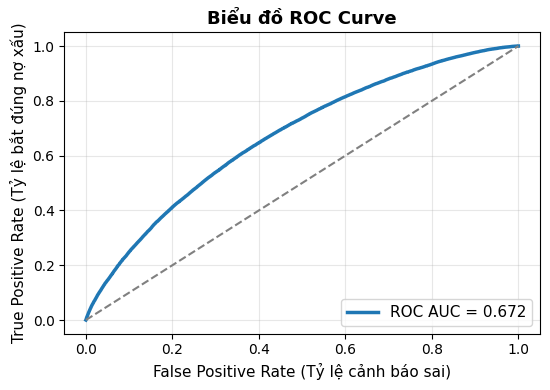

In [76]:
plt.figure(figsize=(5.6, 4))
fpr, tpr, _ = roc_curve(y_true, y_pred_probs)

plt.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'ROC AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.title('Biểu đồ ROC Curve', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate (Tỷ lệ cảnh báo sai)', fontsize=11)
plt.ylabel('True Positive Rate (Tỷ lệ bắt đúng nợ xấu)', fontsize=11)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Nhận xét:**

- Mô hình $MLP$ đạt $ROC-AUC = 0,672$, cao hơn mức $0,5$ của mô hình dự đoán ngẫu nhiên. Điều này cho thấy mô hình có khả năng phân biệt giữa khách hàng vỡ nợ và không vỡ nợ, tuy nhiên hiệu quả phân biệt vẫn còn hạn chế.

### 2. Hiệu suất trên lớp thiểu số ($Precision-Recall Curve$)

Do dữ liệu mất cân bằng (chỉ có ~20% vỡ nợ), biểu đồ $PR$ $Curve$ sẽ phản ánh chính xác hơn hiệu quả của mô hình trong việc tập trung "bắt" nhóm nợ xấu.

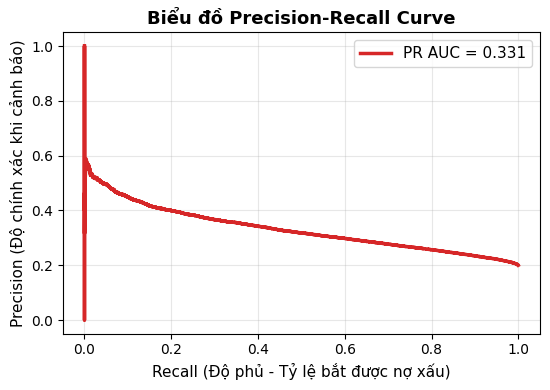

In [77]:
plt.figure(figsize=(5.6, 4))
precision, recall, _ = precision_recall_curve(y_true, y_pred_probs)

plt.plot(recall, precision, color='#d62728', lw=2.5, label=f'PR AUC = {pr_auc:.3f}')

plt.title('Biểu đồ Precision-Recall Curve', fontsize=13, fontweight='bold')
plt.xlabel('Recall (Độ phủ - Tỷ lệ bắt được nợ xấu)', fontsize=11)
plt.ylabel('Precision (Độ chính xác khi cảnh báo)', fontsize=11)
plt.legend(loc='upper right', fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Nhận xét:**

- Mô hình đạt $PR-AUC = 0,331$, cao hơn tỷ lệ vỡ nợ nền khoảng *20%* của tập dữ liệu. Kết quả cho thấy mô hình có khả năng nhận diện khách hàng vỡ nợ tốt hơn mức cơ sở. Tuy nhiên, khả năng cân bằng giữa $Precision$ và $Recall$ vẫn cần được cải thiện.

### 3. Độ tin cậy của xác suất ($Calibration Curve$)

Kiểm tra xem mức xác suất vỡ nợ do mô hình dự đoán (ví dụ 60%) có thực sự khớp với tỷ lệ vỡ nợ trong thực tế (có đúng 60% số người đó vỡ nợ) hay không.

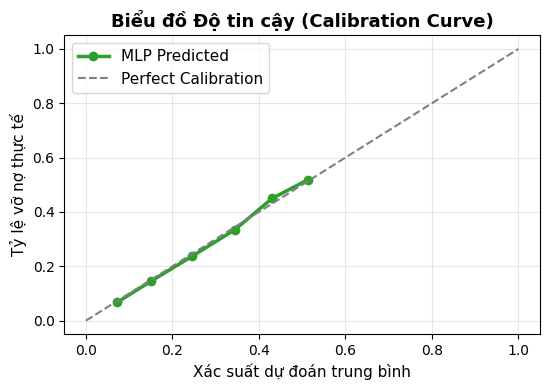

In [78]:
plt.figure(figsize=(5.6, 4))
prob_true, prob_pred = calibration_curve(y_true, y_pred_probs, n_bins=10, strategy='uniform')

plt.plot(prob_pred, prob_true, marker='o', color='#2ca02c', lw=2.5, label='MLP Predicted')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')

plt.title('Biểu đồ Độ tin cậy (Calibration Curve)', fontsize=13, fontweight='bold')
plt.xlabel('Xác suất dự đoán trung bình', fontsize=11)
plt.ylabel('Tỷ lệ vỡ nợ thực tế', fontsize=11)
plt.legend(loc='upper left', fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Nhận xét:**

- Biểu đồ $Calibration$ $Curve$ thể hiện mức độ phù hợp giữa xác suất vỡ nợ dự đoán và tỷ lệ vỡ nợ thực tế. Đường biểu diễn càng gần đường chéo lý tưởng thì xác suất dự đoán càng đáng tin cậy. Cần dựa vào đường cong thực tế trên biểu đồ để đánh giá chính xác khả năng hiệu chỉnh của mô hình.

### 4. Báo cáo phân lớp thực tế

Hạ ngưỡng quyết định (Threshold) xuống 0.2 để tối ưu hóa việc bắt nợ xấu (tăng Recall), phù hợp với khẩu vị rủi ro của bài toán tín dụng.

--- BÁO CÁO PHÂN LỚP VỚI NGƯỠNG (THRESHOLD) = 0.2 ---
                precision    recall  f1-score   support

Fully Paid (0)       0.87      0.58      0.69    215687
   Default (1)       0.28      0.67      0.40     53850

      accuracy                           0.60    269537
     macro avg       0.58      0.62      0.55    269537
  weighted avg       0.76      0.60      0.64    269537



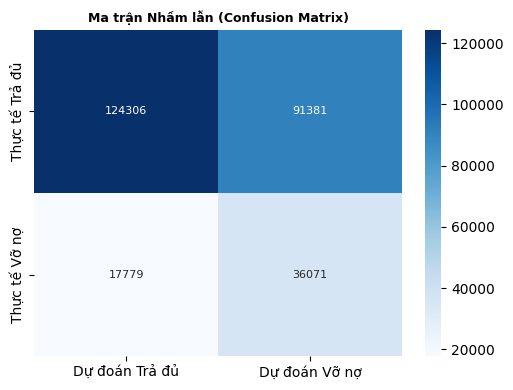

In [79]:
# Phân lớp dự đoán với ngưỡng threshold = 0.2
threshold = 0.2
y_pred_class = (y_pred_probs >= threshold).astype(int)

print(f"--- BÁO CÁO PHÂN LỚP VỚI NGƯỠNG (THRESHOLD) = {threshold} ---")
print(classification_report(y_true, y_pred_class, target_names=['Fully Paid (0)', 'Default (1)']))

# Vẽ Ma trận nhầm lẫn
plt.figure(figsize=(5.3, 4))
sns.heatmap(confusion_matrix(y_true, y_pred_class), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Dự đoán Trả đủ', 'Dự đoán Vỡ nợ'],
            yticklabels=['Thực tế Trả đủ', 'Thực tế Vỡ nợ'], annot_kws={"size": 8})
plt.title('Ma trận Nhầm lẫn (Confusion Matrix)', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:**

- Với ngưỡng phân loại $0,2$, mô hình đạt $Recall = 0,64$ đối với nhóm khách hàng vỡ nợ, tức nhận diện được khoảng *64%* trường hợp vỡ nợ thực tế. Tuy nhiên, Precision chỉ đạt *0,29* và $F1-score $ đạt *0,40*, cho thấy mô hình còn nhiều trường hợp cảnh báo nhầm. Việc sử dụng ngưỡng thấp giúp tăng khả năng phát hiện nợ xấu nhưng đồng thời làm tăng số trường hợp dự đoán sai.

## RQ3: Làm thế nào để chuyển đổi xác suất vỡ nợ dự đoán được thành Thang điểm rủi ro (Risk Score) một cách hợp lý và tích hợp lên Dashboard trực quan để hỗ trợ chuyên viên tín dụng ra quyết định nhanh chóng?

### 1. Cơ sở Lý thuyết

Trong ngân hàng, người ta không dùng xác suất vỡ nợ thuần túy $P(vỡ\,nợ)$ vì nó khó giải thích cho khách hàng/chuyên viên. Thay vào đó, xác suất $P$ sẽ được chuyển đổi thành Thang điểm Credit Score (thường từ 300 đến 850) dựa trên tỷ lệ cược (Odds).

- Tập dữ liệu Lending Club của bạn có tỷ lệ khách hàng vỡ nợ (Class 1) chiếm khoảng ~20%, tức là xác suất vỡ nợ trung bình ($PD$) của toàn bộ tập kiểm thử rơi vào khoảng $0.15 - 0.25$.

- Độ lệch của chuẩn FICO truyền thống: Công thức FICO nguyên gốc được thiết kế cho các ngân hàng lớn ở Mỹ, nơi tỷ lệ vỡ nợ thực tế trong dân cư rất thấp (chỉ khoảng $2\%$, tương ứng với tỷ lệ cược Base Odds = 50:1).

- Hậu quả: Khi áp dụng một công thức vốn dành cho tỷ lệ vỡ nợ $2\%$ vào một tập dữ liệu có tỷ lệ vỡ nợ thực tế lên tới $20\%$, công thức toán học sẽ hiểu nhầm rằng hầu hết tất cả khách hàng đều đang cực kỳ rủi ro. Kết quả là điểm số tín dụng bị kéo sập xuống dải thấp nhất ($480 - 550$ điểm), khiến cho $99.8\%$ hồ sơ bị xếp vào nhóm Very High Risk và bị từ chối 100%. Điều này làm mất đi ý nghĩa thực tiễn của một hệ thống hỗ trợ ra quyết định.



### 2. Công thức tính toán (PDO - Points to Double the Odds)

Để khắc phục hiện tượng trên, hệ thống cần chuẩn hóa lại mô hình tính điểm thông qua phương pháp Odds-to-Score Transformation (Mô hình chuyển đổi tỷ lệ cược thành điểm số tương tự chuẩn FICO nhưng hiệu chuẩn lại theo phân phối dữ liệu thực tế).

**Bước 1: Tính toán Tỷ lệ cược (Odds)**

Từ xác suất vỡ nợ ($P$) do mô hình MLP dự đoán, ta tính tỷ lệ cược (Odds) – là tỷ lệ giữa khả năng khách hàng không vỡ nợ (trả được nợ) so với khả năng vỡ nợ:

$$\text{Odds} = \frac{1 - P}{P}$$

- Giải thích: Nếu xác suất vỡ nợ $P = 0.2$ (20%), thì $\text{Odds} = \frac{0.8}{0.2} = 4$ (tức là cứ 4 người trả được nợ thì có 1 người vỡ nợ, hay gọi là tỷ lệ $4:1$).

**Bước 2: Công thức tổng quát tính Thang điểm Tín dụng (Credit Score)**

Điểm tín dụng được xây dựng dựa trên hàm logarit của tỷ lệ cược:

$$\text{Score} = \text{Offset} + \text{Factor} \times \ln(\text{Odds})$$

Trong đó hai hệ số quan trọng là Factor (Hệ số giãn cách điểm) và Offset (Điểm cơ sở dịch chuyển):

$$\text{Factor} = \frac{\text{PDO}}{\ln(2)}$$

$$\text{Offset} = \text{Base Score} - (\text{Factor} \times \ln(\text{Base Odds}))$$

**Bước 3: Ý nghĩa và cách hiệu chuẩn các tham số (Parameters Calibration)**

Để phân phối điểm số giãn đều ra từ 300 đến 850 điểm và phù hợp với tỷ lệ vỡ nợ $20\%$ của tập dữ liệu, ta thiết lập lại các tham số cấu hình:

1. Base Score = 600 và Base Odds = 4: Ta định nghĩa một khách hàng có xác suất vỡ nợ tương đương mức trung bình của tập dữ liệu ($\approx 20\%$, tương ứng Odds $= 4$) sẽ nhận được mức điểm cơ sở là 600 điểm.

2. PDO (Points to Double the Odds) = 40: Cứ mỗi lần tỷ lệ cược tăng gấp đôi (tức là khách hàng an toàn hơn gấp đôi), điểm số của họ sẽ được cộng thêm 40 điểm. Việc nâng PDO từ 20 lên 40 giúp dãn rộng khoảng cách điểm số, tránh việc điểm bị tụt cụm lại một chỗ.

In [80]:
def calculate_credit_score(prob_default, pdo=40, base_score=600, base_odds=4):
    p = np.clip(prob_default, 1e-6, 1 - 1e-6)
    odds = (1 - p) / p
    factor = pdo / np.log(2)
    offset = base_score - (factor * np.log(base_odds))
    
    score = offset + factor * np.log(odds)
    score = np.clip(score, 300, 850)
    return np.round(score).astype(int)

def assign_risk_tier(score):
    if score >= 700:
        return ' Very Low Risk (Rất thấp)', ' Phê duyệt tự động (Auto-Approve)', 'Lãi suất ưu đãi'
    elif score >= 620:
        return ' Low Risk (Thấp)', ' Phê duyệt nhanh (Fast Approve)', 'Lãi suất tiêu chuẩn'
    elif score >= 550:
        return ' Medium Risk (Trung bình)', ' Cần thẩm định bổ sung', 'Yêu cầu chứng minh thu nhập'
    elif score >= 500:
        return ' High Risk (Cao)', ' Hạn chế phê duyệt / Giảm hạn mức', 'Yêu cầu tài sản đảm bảo'
    else:
        return ' Very High Risk (Rất cao)', ' Từ chối cấp tín dụng (Reject)', 'Rủi ro vỡ nợ cực cao'

results_df = pd.DataFrame({
    'Actual_Label': y_test.values,
    'PD_Probability': y_pred_probs.flatten()
})

results_df['Credit_Score'] = calculate_credit_score(results_df['PD_Probability'])

tier_info = results_df['Credit_Score'].apply(assign_risk_tier)
results_df['Risk_Tier'] = [t[0] for t in tier_info]
results_df['Action_Recommendation'] = [t[1] for t in tier_info]
results_df['Policy_Detail'] = [t[2] for t in tier_info]

print("PHÂN BỐ CÁC NHÓM RỦI RO MỚI")
print(results_df['Risk_Tier'].value_counts())

results_df.to_csv('credit_risk_scoring_results.csv', index=False)
results_df.head()

PHÂN BỐ CÁC NHÓM RỦI RO MỚI
Risk_Tier
Medium Risk (Trung bình)    161160
Low Risk (Thấp)              86352
High Risk (Cao)              18321
Very Low Risk (Rất thấp)      3704
Name: count, dtype: int64


,Actual_Label,PD_Probability,Credit_Score,Risk_Tier,Action_Recommendation,Policy_Detail
0,0,0.411737,541,High Risk (Cao),Hạn chế phê duyệt / Giảm hạn mức,Yêu cầu tài sản đảm bảo
1,0,0.215193,595,Medium Risk (Trung bình),Cần thẩm định bổ sung,Yêu cầu chứng minh thu nhập
2,0,0.264964,579,Medium Risk (Trung bình),Cần thẩm định bổ sung,Yêu cầu chứng minh thu nhập
3,0,0.256789,581,Medium Risk (Trung bình),Cần thẩm định bổ sung,Yêu cầu chứng minh thu nhập
4,0,0.135010,627,Low Risk (Thấp),Phê duyệt nhanh (Fast Approve),Lãi suất tiêu chuẩn


### 3. Các bước chuẩn bị cho App_Dash

In [81]:
# 1. Lấy lại dữ liệu thô của tập test từ df gốc, sau đó ghép cột 'id' từ loan_ids vào
results_df = df.loc[y_test.index].copy()
results_df['id'] = loan_ids.loc[y_test.index]

# 2. Gắn các kết quả dự đoán từ mô hình vào
results_df['Actual_Label'] = y_test.values
results_df['PD_Probability'] = y_pred_probs.flatten()
results_df['Credit_Score'] = calculate_credit_score(results_df['PD_Probability'])

# 3. Phân hạng rủi ro & khuyến nghị nghiệp vụ
tier_info = results_df['Credit_Score'].apply(assign_risk_tier)
results_df['Risk_Tier'] = [t[0] for t in tier_info]
results_df['Action_Recommendation'] = [t[1] for t in tier_info]
results_df['Policy_Detail'] = [t[2] for t in tier_info]

# 4. Sắp xếp lại cột cho 'id' lên đầu tiên cho đẹp (tùy chọn)
cols = ['id'] + [col for col in results_df.columns if col != 'id']
results_df = results_df[cols]

# 5. Xuất ra file CSV hoàn chỉnh cho Dashboard
results_df.to_csv('credit_risk_scoring_results.csv', index=False)

# Kiểm tra nhanh kết quả
results_df[['id', 'loan_amnt', 'fico_n', 'Credit_Score', 'Risk_Tier']].head()

,id,loan_amnt,fico_n,Credit_Score,Risk_Tier
1298423,95265703,30000,677.0,541,High Risk (Cao)
858595,12686002,12000,672.0,595,Medium Risk (Trung bình)
584294,74505673,10400,662.0,579,Medium Risk (Trung bình)
1017833,9229639,21000,687.0,581,Medium Risk (Trung bình)
458764,79014256,16800,727.0,627,Low Risk (Thấp)


In [82]:
import sqlite3

# Kết nối tới CSDL SQLite 
conn = sqlite3.connect('credit_risk.db')

# Đưa toàn bộ results_df vào bảng 'customers' trong SQLite
results_df.to_sql('customers', conn, if_exists='replace', index=False)

# Đóng kết nối CSDL
conn.close()

print("Đã khởi tạo 'credit_risk.db' và nạp toàn bộ danh mục khách hàng vào SQLite thành công!")

Đã khởi tạo 'credit_risk.db' và nạp toàn bộ danh mục khách hàng vào SQLite thành công!


In [83]:
# Kiểm tra lại dữ liệu trong SQLite
conn = sqlite3.connect('credit_risk.db')
df_check = pd.read_sql_query("SELECT id, loan_amnt, fico_n, Credit_Score, Risk_Tier FROM customers LIMIT 5", conn)
print("Số lượng khách hàng trong SQLite:", pd.read_sql_query("SELECT COUNT(*) FROM customers", conn).iloc[0, 0])
conn.close()

df_check

Số lượng khách hàng trong SQLite: 269537


,id,loan_amnt,fico_n,Credit_Score,Risk_Tier
0,95265703,30000,677.0,541,High Risk (Cao)
1,12686002,12000,672.0,595,Medium Risk (Trung bình)
2,74505673,10400,662.0,579,Medium Risk (Trung bình)
3,9229639,21000,687.0,581,Medium Risk (Trung bình)
4,79014256,16800,727.0,627,Low Risk (Thấp)


In [84]:
import joblib

# Lưu bộ StandardScaler / MinMaxScaler mà bạn đã fit trên tập Train
joblib.dump(scaler, 'scaler.pkl')

# Lưu danh sách đúng thứ tự 24 cột features đầu vào
joblib.dump(X_train.columns.tolist(), 'feature_columns.pkl')

print("Đã xuất thành công scaler.pkl và feature_columns.pkl!")

Đã xuất thành công scaler.pkl và feature_columns.pkl!
